# Module 3: Data Exploration

The following tutorial contains examples of Python code for data exploration. You should refer to the "Data Exploration" chapter of the "Introduction to Data Mining" book (available at https://www-users.cs.umn.edu/~kumar001/dmbook/index.php) to understand some of the concepts introduced in this tutorial notebook.

Data exploration refers to the preliminary investigation of data in order
to better understand its specific characteristics. There are two key motivations for data exploration:
1. To help users select the appropriate preprocessing and data analysis technique used.
2. To make use of humans' abilities to recognize patterns in the data.

Read the step-by-step instructions below carefully. To execute the code, click on the cell and press the SHIFT-ENTER keys simultaneously.

## 3.1. Summary Statistics

Summary statistics are quantities, such as the mean and standard deviation, that capture various characteristics of a potentially large set of values with a single number or a small set of numbers. In this tutorial, we will use the Iris sample data, which contains information on 150 Iris flowers, 50 each from one of three Iris species: Setosa, Versicolour, and Virginica. Each flower is characterized by five attributes:

- sepal length in centimeters

- sepal width in centimeters

- petal length in centimeters

- petal width in centimeters

- class (Setosa, Versicolour, Virginica) 

In this tutorial, you will learn how to:

- Load a CSV data file into a Pandas DataFrame object.

- Compute various summary statistics from the DataFrame.

To execute the sample program shown here, make sure you have installed the Pandas library (see Module 2).

**1.** First, you need to download the <a href="http://archive.ics.uci.edu/ml/datasets/Iris">Iris dataset</a> from the UCI machine learning repository.

**<font color='red'>Code:</font>** The following code uses Pandas to read the CSV file and store them in a DataFrame object named data. Next, it will display the first five rows of the data frame.

In [22]:
import pandas as pd

data = pd.read_csv('http://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data',header=None)
data.columns = ['sepal length', 'sepal width', 'petal length', 'petal width', 'class']

data.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


**2.** For each quantitative attribute, calculate its mean, median, mode, standard deviation, minimum, and maximum values. An attribute can have more than one mode.

**<font color="red">Code:</font>**

In [23]:
from pandas.api.types import is_numeric_dtype

# Summarize each quantitative attribute, retaining all modes.
for col in data.columns:
    if is_numeric_dtype(data[col]):
        print('%s:' % (col))
        print('\t Mean = %.2f' % data[col].mean())
        print('\t Median = %.2f' % data[col].median())
        print('\t Mode =', ', '.join('%.2f' % value for value in data[col].mode()))
        print('\t Standard deviation = %.2f' % data[col].std())
        print('\t Minimum = %.2f' % data[col].min())
        print('\t Maximum = %.2f' % data[col].max())

sepal length:
	 Mean = 5.84
	 Median = 5.80
	 Mode = 5.00
	 Standard deviation = 0.83
	 Minimum = 4.30
	 Maximum = 7.90
sepal width:
	 Mean = 3.05
	 Median = 3.00
	 Mode = 3.00
	 Standard deviation = 0.43
	 Minimum = 2.00
	 Maximum = 4.40
petal length:
	 Mean = 3.76
	 Median = 4.35
	 Mode = 1.50
	 Standard deviation = 1.76
	 Minimum = 1.00
	 Maximum = 6.90
petal width:
	 Mean = 1.20
	 Median = 1.30
	 Mode = 0.20
	 Standard deviation = 0.76
	 Minimum = 0.10
	 Maximum = 2.50


**3.** For the qualitative attribute (class), count the frequency for each of its distinct values.

**<font color="red">Code:</font>**

In [24]:
data['class'].value_counts()

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

**4.** It is also possible to display the summary for all the attributes simultaneously in a table using the describe() function. If an attribute is quantitative, it will display its mean, standard deviation and various quantiles (including minimum, median, and maximum) values. If an attribute is qualitative, it will display its number of unique values and the top (most frequent) values. 

**<font color="red">Code:</font>**

In [25]:
data.describe(include='all')

,sepal length,sepal width,petal length,petal width,class
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.054000,3.758667,1.198667,NaN
std,0.828066,0.433594,1.764420,0.763161,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


Note that count refers to the number of non-missing values for each attribute.

**5.** For multivariate statistics, you can compute the covariance and correlation between pairs of attributes.

**Covariance** measures how two variables vary together (absolute scale), **correlation** measures the strength and direction of linear relationships (scaled between -1 and 1).

**Correlation is covariance normalized by the standard deviations** of the two variables:

Covariance tells you whether the variables tend to move together, but its magnitude depends on their units and scales. Dividing by the standard deviations removes those units and gives a value between **−1 and 1**:

- **+1:** a perfect positive linear relationship.
- **−1:** a perfect negative linear relationship.
- **0:** no linear relationship, though a nonlinear relationship may still exist.

For example, changing height from meters to centimeters changes its covariance with weight, but leaves their correlation unchanged.

**<font color="red">Code:</font>**

In [26]:
print('Covariance:')
numeric_data = data.select_dtypes(include=['number'])

numeric_data.cov()

Covariance:


,sepal length,sepal width,petal length,petal width
sepal length,0.685694,-0.039268,1.273682,0.516904
sepal width,-0.039268,0.188004,-0.321713,-0.117981
petal length,1.273682,-0.321713,3.113179,1.296387
petal width,0.516904,-0.117981,1.296387,0.582414


In [27]:
print('Correlation:')
numeric_data.corr()

Correlation:


,sepal length,sepal width,petal length,petal width
sepal length,1.000000,-0.109369,0.871754,0.817954
sepal width,-0.109369,1.000000,-0.420516,-0.356544
petal length,0.871754,-0.420516,1.000000,0.962757
petal width,0.817954,-0.356544,0.962757,1.000000


## 3.2. Data Visualization

Data visualization is the display of information in a graphic or tabular format. Successful visualization requires that the data (information) be converted into a visual format so that the characteristics of the data and the relationships
among data items or attributes can be analyzed or reported.

In this tutorial, you will learn how to display the Iris data created in Section 3.1. To execute the sample program shown here, make sure you have installed the matplotlib library package (see Module 0 on how to install Python packages).

**1.** First, we will display the histogram for the sepal length attribute by discretizing it into 8 separate bins and counting the frequency for each bin.

**<font color="red">Code:</font>**

<Axes: >

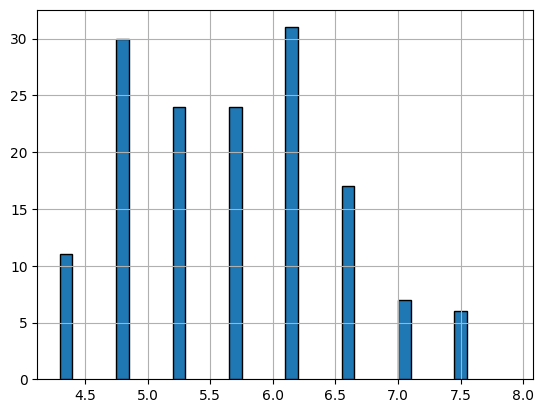

In [36]:
import matplotlib.pyplot as plt

#data['sepal length'].hist()
data['sepal length'].hist(width=0.1, bins=8, edgecolor='black')

**2.** Use boxplots to show the distribution of each quantitative attribute. Create three separate plots:

1. Use the default boxplot settings.
2. Set the whiskers to the minimum and maximum values.
3. Choose lower and upper percentiles for the whiskers, and show the mean as the central line in each box.

**<font color="red">Code:</font>**

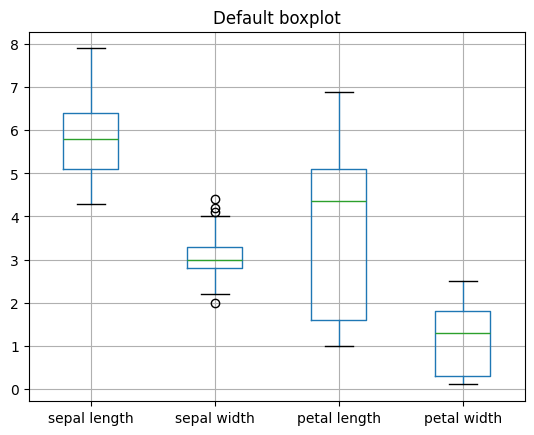

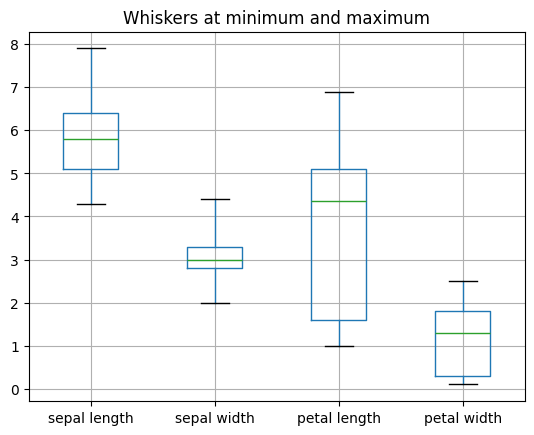

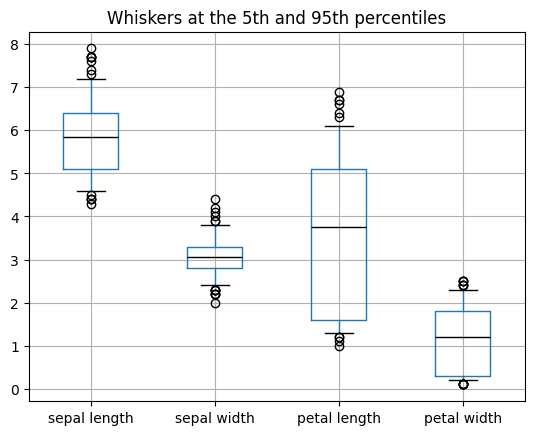

In [29]:
import matplotlib.pyplot as plt

# Use only the quantitative attributes for all three plots.
numeric_data = data.select_dtypes(include=['number'])

# Plot the default boxplot.
numeric_data.boxplot()
plt.title('Default boxplot')
plt.show()

# Extend the whiskers to the minimum and maximum values.
numeric_data.boxplot(whis=(0, 100))
plt.title('Whiskers at minimum and maximum')
plt.show()

# Choose whisker percentiles and display the mean as the central line.
lower_percentile, upper_percentile = 5, 95
numeric_data.boxplot(whis=(lower_percentile, upper_percentile),
                     showmeans=True, meanline=True,
                     meanprops={'color': 'black', 'linestyle': '-'},
                     medianprops={'visible': False})
plt.title(f'Whiskers at the {lower_percentile}th and {upper_percentile}th percentiles')
plt.show()

**3.** For each pair of attributes, we can use a scatter plot to visualize their joint distribution.

**<font color="red">Code:</font>**

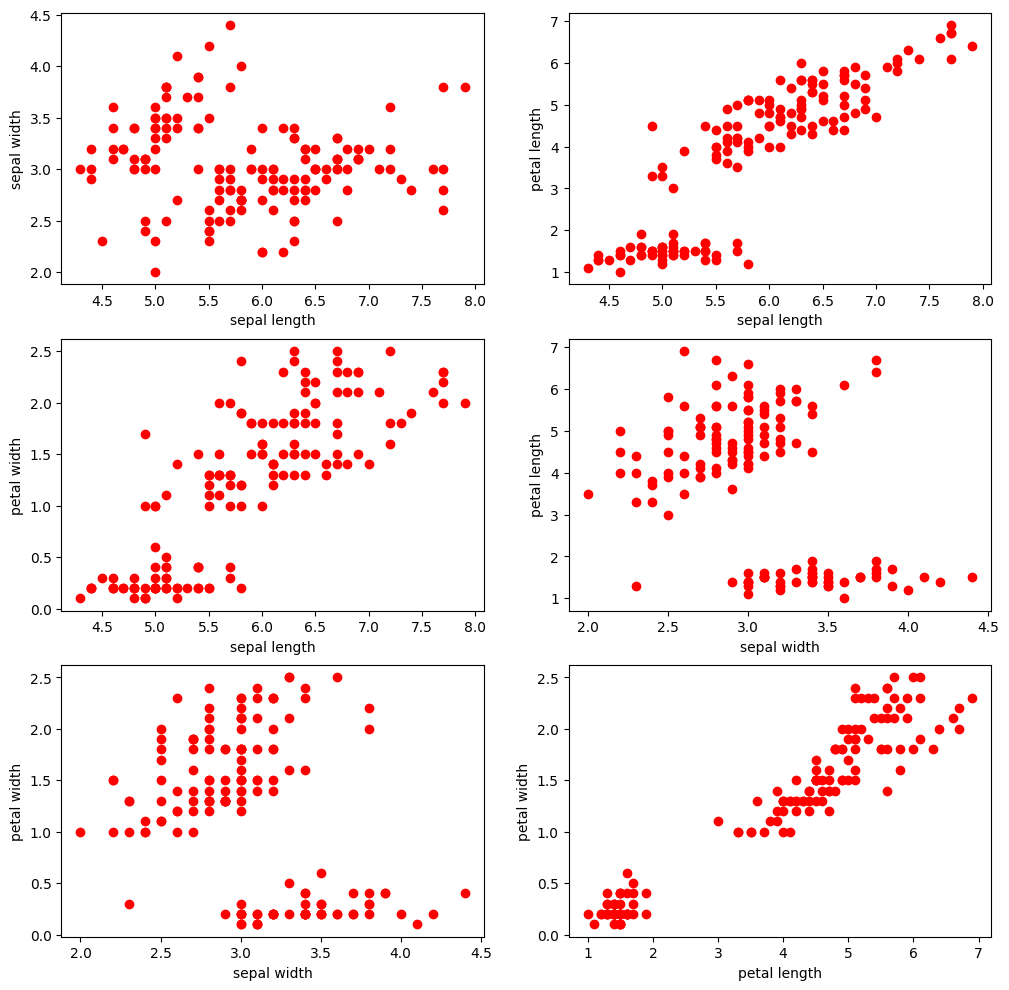

In [30]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(12,12))
index = 0
for i in range(3):
    for j in range(i+1,4):
        ax1 = int(index/2)
        ax2 = index % 2
        axes[ax1][ax2].scatter(data[data.columns[i]], data[data.columns[j]], color='red')
        axes[ax1][ax2].set_xlabel(data.columns[i])
        axes[ax1][ax2].set_ylabel(data.columns[j])
        index = index + 1

**4.** Parallel coordinates can be used to display all the data points simultaneously. Parallel coordinates have one coordinate axis for each attribute, but the different axes are parallel to one other instead of perpendicular, as is traditional. Furthermore, an object is represented as a line instead of as a point. In the example below, the distribution of values for each class can be identified in a separate color.

**<font color="red">Code:</font>**

<Axes: >

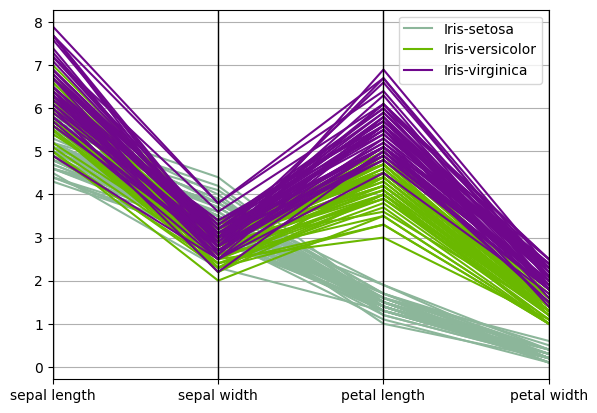

In [31]:
from pandas.plotting import parallel_coordinates

parallel_coordinates(data, 'class')

**5.** Create three grouped bar plots: one each for the mean, median, and mode. In each plot, compare the three classes across all quantitative attributes. Show all modes when an attribute has more than one.

**<font color="red">Code:</font>**

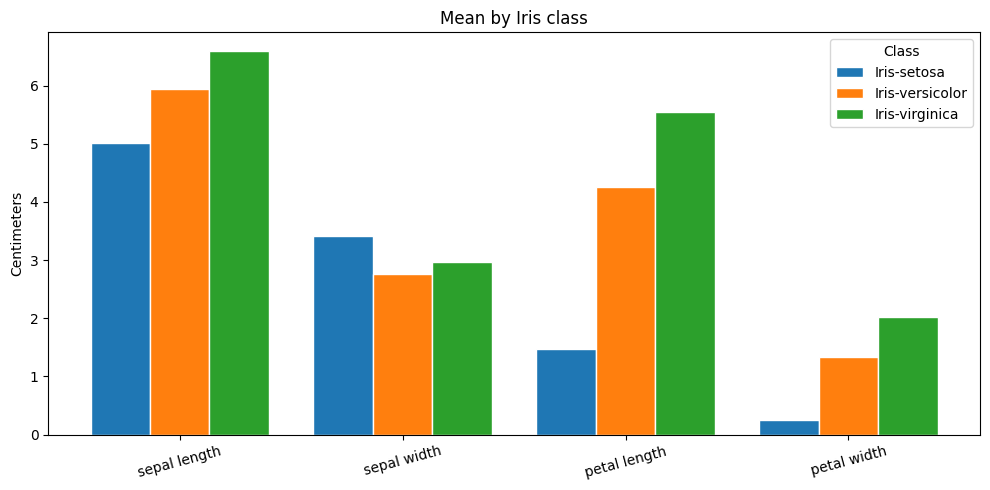

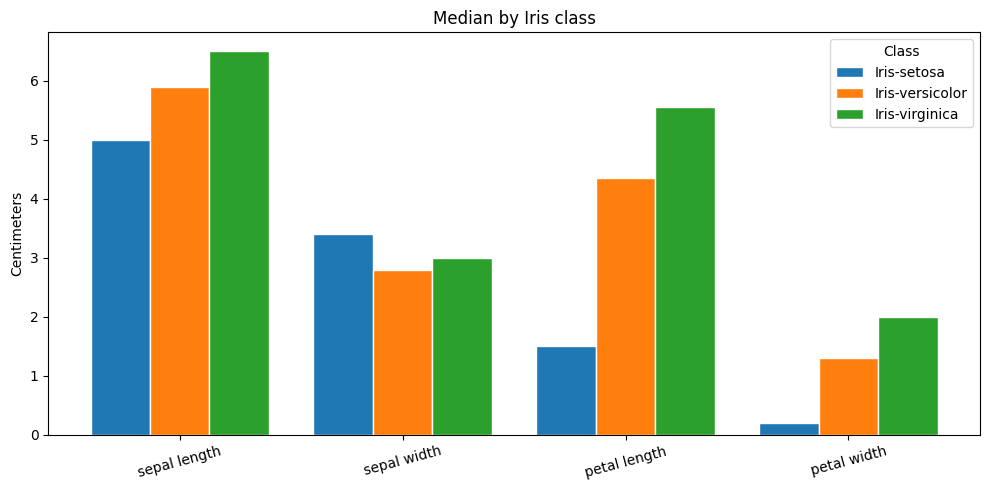

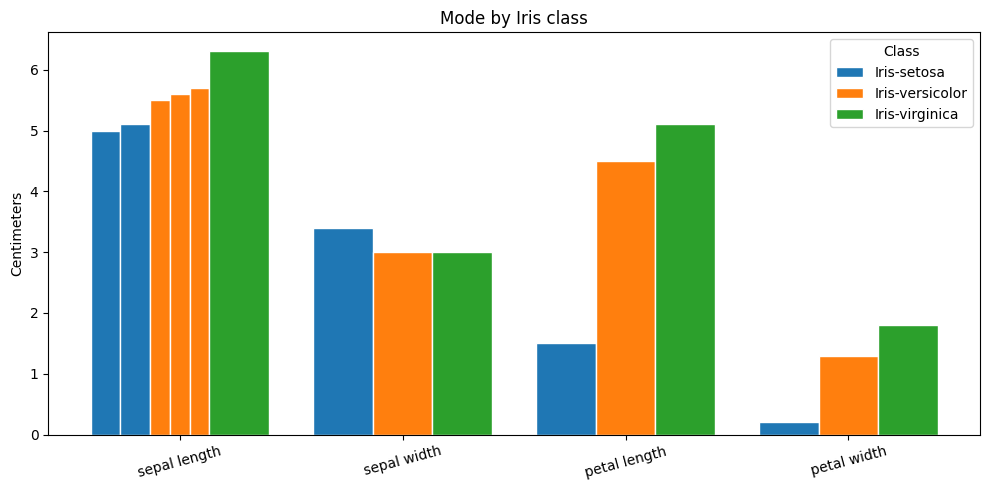

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Group the quantitative attributes by Iris class.
attributes = data.select_dtypes(include=['number']).columns
classes = data['class'].dropna().unique()
positions = np.arange(len(attributes))
class_width = 0.8 / len(classes)

# Create one figure for each statistic, with a group of bars per attribute.
for statistic in ['mean', 'median', 'mode']:
    fig, ax = plt.subplots(figsize=(10, 5))
    for class_index, class_name in enumerate(classes):
        class_data = data.loc[data['class'] == class_name, attributes]
        color = f'C{class_index}'
        for attribute_index, attribute in enumerate(attributes):
            values = (class_data[attribute].mode().tolist() if statistic == 'mode'
                      else [getattr(class_data[attribute], statistic)()])
            # Split the class's allotted space when there are multiple modes.
            bar_width = class_width / max(len(values), 1)
            for value_index, value in enumerate(values):
                x = (positions[attribute_index] - 0.4 + class_index * class_width
                     + (value_index + 0.5) * bar_width)
                label = class_name if attribute_index == 0 and value_index == 0 else None
                ax.bar(x, value, width=bar_width, color=color, edgecolor='white', label=label)
    ax.set_xticks(positions)
    ax.set_xticklabels(attributes, rotation=15)
    ax.set_ylabel('Centimeters')
    ax.set_title(f'{statistic.title()} by Iris class')
    ax.legend(title='Class')
    fig.tight_layout()
    plt.show()

**6.** Choose a quantitative attribute and create the following plots:

1. **Quantile plot:** Sort all values of the attribute and plot each value against its cumulative fraction. For a sorted value $x_i$, approximately $100f_i$% of observations are less than or equal to $x_i$. Use the plot to inspect the overall distribution and unusual values.
2. **Quantile-quantile (Q-Q) plot:** Choose two Iris classes and plot corresponding quantiles of the attribute for one class against those of the other. Add a reference line and consider whether the distributions appear shifted relative to one another.

Class A’s is on the horizontal axis, and class B is on the vertical axis: 
- Points close to the diagonal: corresponding values are similar.
- Points mostly above the diagonal: class B tends to have larger values than class A.
- Points forming a roughly straight line above the diagonal: the distributions may have a similar shape, with class B shifted upward.
- A curved pattern or points spreading away from a straight line: the distributions may differ in spread or shape.

**<font color="red">Code:</font>**

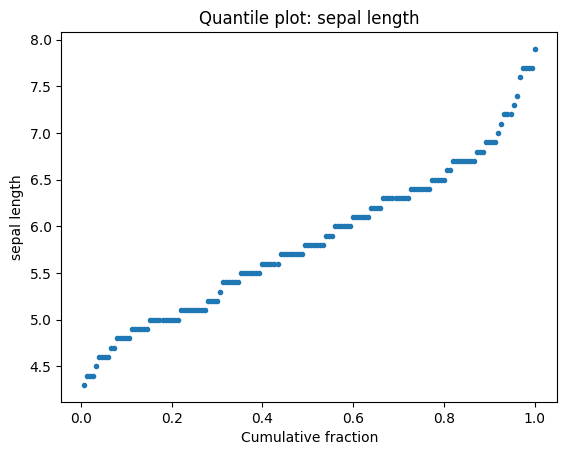

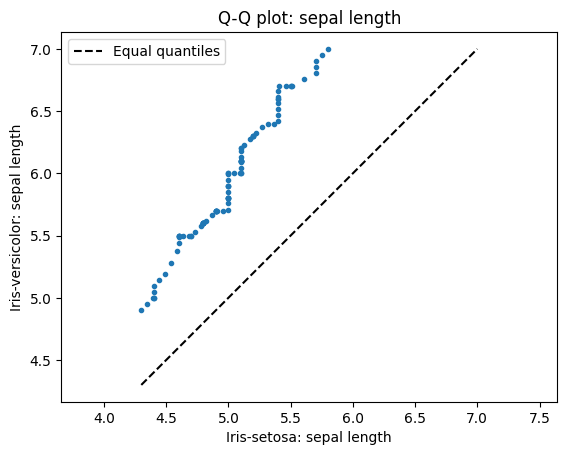

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Choose an attribute and two classes to compare.
attribute = 'sepal length'
class_x = 'Iris-setosa'
class_y = 'Iris-versicolor'

# Plot each sorted observation against its cumulative fraction.
values = np.sort(data[attribute].dropna().to_numpy())
fractions = np.arange(1, len(values) + 1) / len(values)
plt.figure()
plt.plot(fractions, values, '.')
plt.xlabel('Cumulative fraction')
plt.ylabel(attribute)
plt.title(f'Quantile plot: {attribute}')
plt.show()

# Evaluate both class distributions at the same quantile levels.
x = data.loc[data['class'] == class_x, attribute].dropna().to_numpy()
y = data.loc[data['class'] == class_y, attribute].dropna().to_numpy()
levels = np.linspace(0, 1, 101)
x_quantiles = np.quantile(x, levels)
y_quantiles = np.quantile(y, levels)

# The identity line makes shifts between the distributions visible.
limits = [min(x_quantiles.min(), y_quantiles.min()),
          max(x_quantiles.max(), y_quantiles.max())]
plt.figure()
plt.plot(x_quantiles, y_quantiles, '.')
plt.plot(limits, limits, '--', color='black', label='Equal quantiles')
plt.xlabel(f'{class_x}: {attribute}')
plt.ylabel(f'{class_y}: {attribute}')
plt.title(f'Q-Q plot: {attribute}')
plt.legend()
plt.axis('equal')
plt.show()

## 3.3. Summary

This tutorial presents several examples for data exploration and visualization using the Pandas and matplotlib library packages available in Python. 

**<font color='blue'>References:</font>**

1. Documentation on Pandas. https://pandas.pydata.org/
2. Documentation on matplotlib. https://matplotlib.org/
3. Lichman, M. (2013). UCI Machine Learning Repository [http://archive.ics.uci.edu/ml]. Irvine, CA: University of California, School of Information and Computer Science. 